# TechFest Face Recognition Challenge — Pakistani Context
**Pipeline:** RetinaFace/SCRFD detection → 5-point alignment & crop → quality gate + low-light enhancement → AdaFace IR-101 (fine-tuned) embeddings → cosine matching with a validation-calibrated threshold.

Runtime → Change runtime type → **T4 GPU**. Run the cells top to bottom.

Folder on Google Drive (create it once):
```
MyDrive/NemoFR/
   facerec_pk.zip          <- this project (upload once)
   data/raw/               <- one folder per consenting participant (P001/, P002/ ...) + identities.csv
```

In [ ]:

from google.colab import drive
drive.mount('/content/drive')

import os
import zipfile

# Google Drive paths
DRIVE = '/content/drive/MyDrive/NemoFR (1)'
RAW   = f'{DRIVE}/data/raw'
WORK  = '/content/work'                  # Fast local disk
PROC  = f'{WORK}/processed'
RUNS  = f'{DRIVE}/runs'                  # Persistent results on Drive

os.makedirs(WORK, exist_ok=True)
os.makedirs(PROC, exist_ok=True)
os.makedirs(RUNS, exist_ok=True)

# Check ZIP file
ZIP_PATH = f'{DRIVE}/facerec_pk.zip'
assert os.path.isfile(ZIP_PATH), f'ZIP not found: {ZIP_PATH}'

# Extract project
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall('/content/')

PROJECT = '/content/facerec_pk'
assert os.path.isdir(PROJECT), f'Project folder not found: {PROJECT}'

# Install requirements
%cd /content/facerec_pk
%pip install -q -r requirements.txt

# Clone AdaFace only if it does not already exist
ADAFACE = '/content/AdaFace'

if not os.path.isdir(os.path.join(ADAFACE, '.git')):
    if os.path.exists(ADAFACE):
        print('AdaFace folder exists but is not a Git repository.')
        print('Check its contents before replacing it.')
    else:
        !git clone -q --depth 1 https://github.com/mk-minchul/AdaFace.git /content/AdaFace
else:
    print('AdaFace repository already exists; reusing it.')

print('Setup paths:')
print('DRIVE  =', DRIVE)
print('PROJECT =', PROJECT)
print('RAW    =', RAW, '| Exists:', os.path.isdir(RAW))
print('WORK   =', WORK)
print('PROC   =', PROC)
print('RUNS   =', RUNS)
print('ADAFACE =', ADAFACE)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/facerec_pk
AdaFace repository already exists; reusing it.
Setup paths:
DRIVE  = /content/drive/MyDrive/NemoFR (1)
PROJECT = /content/facerec_pk
RAW    = /content/drive/MyDrive/NemoFR (1)/data/raw | Exists: True
WORK   = /content/work
PROC   = /content/work/processed
RUNS   = /content/drive/MyDrive/NemoFR (1)/runs
ADAFACE = /content/AdaFace


In [ ]:
import os
import zipfile

DRIVE = "/content/drive/MyDrive/NemoFR (1)"
ZIP_PATH = os.path.join(DRIVE, "facerec_pk.zip")
PROJECT = "/content/facerec_pk"

print("ZIP exists:", os.path.isfile(ZIP_PATH))

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    print("ZIP top-level entries:", z.namelist()[:15])

ZIP exists: True
ZIP top-level entries: ['facerec_pk/', 'facerec_pk/app.py', 'facerec_pk/tools/', 'facerec_pk/tools/build_notebook.py', 'facerec_pk/docs/', 'facerec_pk/docs/CONSENT_AND_DATA_COLLECTION.md', 'facerec_pk/docs/REPORT_TEMPLATE.md', 'facerec_pk/scripts/', 'facerec_pk/scripts/common.py', 'facerec_pk/scripts/evaluate.py', 'facerec_pk/scripts/download_weights.py', 'facerec_pk/scripts/import_halfface.py', 'facerec_pk/scripts/make_submission_grp.py', 'facerec_pk/scripts/import_google_form.py', 'facerec_pk/scripts/enroll_gallery.py']


In [ ]:
import os
import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall("/content")

print("Extraction complete.")

for root, dirs, files in os.walk("/content"):
    dirs[:] = [d for d in dirs if d not in [".git", "node_modules"]]
    if "requirements.txt" in files:
        print("Found requirements:", os.path.join(root, "requirements.txt"))

Extraction complete.
Found requirements: /content/facerec_pk/requirements.txt
Found requirements: /content/AdaFace/requirements.txt


## 1. Setup

In [ ]:
# # from google.colab import drive
# # drive.mount('/content/drive')

# # DRIVE = '/content/drive/MyDrive/NemoFR'
# RAW   = f'{DRIVE}/data/raw'
# WORK  = '/content/work'                 # fast local disk
# PROC  = f'{WORK}/processed'
# RUNS  = f'{DRIVE}/runs'                 # checkpoints + results persist on Drive
# import os; os.makedirs(WORK, exist_ok=True); os.makedirs(RUNS, exist_ok=True)

# !unzip -oq {DRIVE}/facerec_pk.zip -d /content/
# %cd /content/facerec_pk
# !pip install -q -r requirements.txt
# !git clone -q --depth 1 https://github.com/mk-minchul/AdaFace.git /content/AdaFace || true

In [ ]:
  # AdaFace IR-101 (WebFace12M) + InsightFace buffalo_l detector
!python scripts/download_weights.py --name ir_101_webface12m --out {DRIVE}/weights
PRETRAINED = f'{DRIVE}/weights/adaface_ir_101_webface12m.ckpt'
ADAFACE = '/content/AdaFace'
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - switch runtime to GPU')

/bin/bash: -c: line 1: syntax error near unexpected token `('
/bin/bash: -c: line 1: `python scripts/download_weights.py --name ir_101_webface12m --out /content/drive/MyDrive/NemoFR (1)/weights'
GPU: Tesla T4


## 2. Bring in the data
**A. Volunteers via Google Form** (recommended): export the responses Sheet as CSV to Drive and run the cell below.
Skip it if you already copied folders into `data/raw/` yourself.

**B. halfFace** (South Asian, masked + unmasked, smartphone photos): download from Mendeley Data (`pk44mkx9vm`), upload the zip to Drive, set the path of the full-face set below. Used for training only.

In [ ]:
# A. Google Form import (edit column names with --col_* flags if your form differs)
# !python scripts/import_google_form.py --responses {DRIVE}/form_responses.csv --raw {RAW}

# B. halfFace
# !unzip -oq {DRIVE}/halfface.zip -d /content/halfface
# !python scripts/import_halfface.py --src "/content/halfface/<Dataset 1 folder>" --raw {RAW}
# !ls {RAW} | head
# !ls {RAW} | wc -l

## 3. Detect, align, quality-check and split (identity-disjoint)

In [1]:
# !python scripts/prepare_data.py --raw {RAW} --out {PROC} --test_frac 0.2 --val_frac 0.2 --min_images 1
# !zip -qr {RUNS}/processed.zip {PROC}      # backup so you can skip this step after a disconnect
# from IPython.display import Markdown, display
# display(Markdown(open(f'{PROC}/prepare_report.md').read()))

In [ ]:
# After a Colab disconnect, restore instead of re-running step 3:
# !mkdir -p {WORK} && unzip -oq {RUNS}/processed.zip -d /

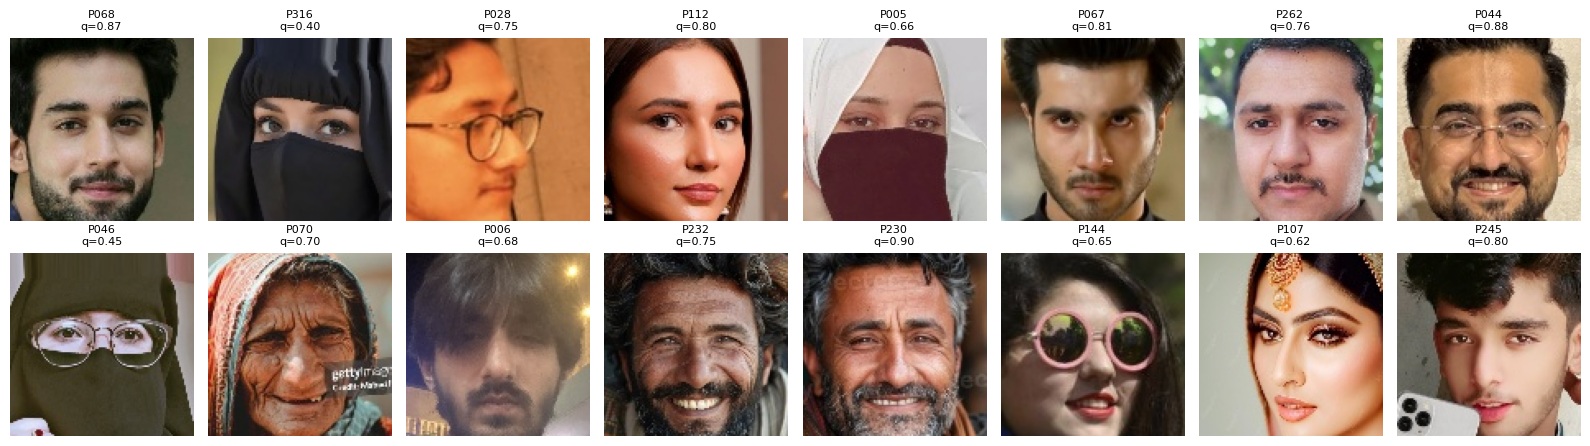

In [ ]:
# Look at a few aligned crops and what the quality gate thinks of them
import pandas as pd, cv2, matplotlib.pyplot as plt
df = pd.read_csv(f'{PROC}/images.csv')
s = df.sample(min(16, len(df)), random_state=0)
fig, axs = plt.subplots(2, 8, figsize=(16, 4.6))
for ax, (_, r) in zip(axs.flat, s.iterrows()):
    ax.imshow(cv2.cvtColor(cv2.imread(f"{PROC}/{r.path_aligned}"), cv2.COLOR_BGR2RGB)); ax.axis('off')
    ax.set_title(f"{r.identity}\nq={r.quality_score:.2f}{'' if r.usable else ' REJ'}", fontsize=8)
plt.tight_layout(); plt.show()

## 4. Fine-tune AdaFace on Pakistani faces
Model selection uses validation identities only. ~2-4 min/epoch on a T4 for ~3k images.

In [ ]:
!python scripts/train.py --data {PROC} --adaface_repo {ADAFACE} --ckpt {PRETRAINED} \
        --out {RUNS}/ft --epochs 12 --batch 64 --unfreeze_blocks 6 --distill 1.0
FINETUNED = f'{RUNS}/ft/best.pt'

train: 265 images / 200 ids | val: 73 images / 69 ids | device=cuda
[epoch 0 | pretrained] val EER=0.0000  TAR@FAR1%=1.0000

\AdaFace with the following property
self.m 0.4
self.h 0.333
self.s 64.0
self.t_alpha 0.01
[epoch 1] ce=4.236 distill=0.0913 val EER=0.0000 TAR@FAR1%=1.0000 (2s)
[epoch 2] ce=3.250 distill=0.0814 val EER=0.0000 TAR@FAR1%=1.0000 (1s)
[epoch 3] ce=3.696 distill=0.0793 val EER=0.0000 TAR@FAR1%=1.0000 (1s)
[epoch 4] ce=3.633 distill=0.0752 val EER=0.0000 TAR@FAR1%=1.0000 (1s)
early stopping
best epoch 0: val EER 0.0000 (pretrained 0.0000)


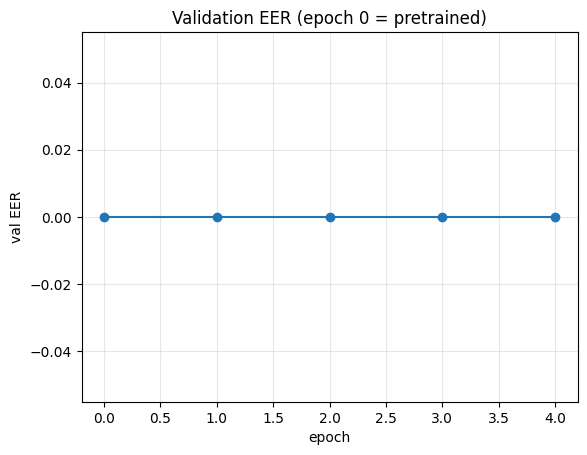

In [ ]:
import json, matplotlib.pyplot as plt
h = json.load(open(f'{RUNS}/ft/train_history.json'))['history']
plt.plot([x['epoch'] for x in h], [x['EER'] for x in h], 'o-'); plt.xlabel('epoch'); plt.ylabel('val EER'); plt.title('Validation EER (epoch 0 = pretrained)'); plt.grid(alpha=.3); plt.show()

## 5. Evaluate: ablation, model comparison, groups, identification

In [ ]:
!python scripts/evaluate.py --data {PROC} --adaface_repo {ADAFACE} --pretrained {PRETRAINED} \
        --finetuned {FINETUNED} --with_arcface --out {RUNS}/results
from IPython.display import Markdown, display
display(Markdown(open(f'{RUNS}/results/results_summary.md').read()))

val: 9 ids, 76 pairs | test: 9 ids, 30 pairs
A0  pretrained AdaFace, bbox crop (no alignment)        test EER=0.0000 acc=0.9667 F1=0.9677
A1  + 5-point alignment                                 test EER=0.0000 acc=1.0000 F1=1.0000
A2  + quality enhancement (CLAHE/gamma)                 test EER=0.0000 acc=0.9667 F1=0.9677
A3  + flip test-time augmentation                       test EER=0.0000 acc=0.9667 F1=0.9677
A4  + fine-tuned on Pakistani data (FULL PIPELINE)      test EER=0.0000 acc=0.9667 F1=0.9677
ref ArcFace R50 (InsightFace) with same pipeline        test EER=0.0000 acc=0.9667 F1=0.9677

Saved results to /content/drive/MyDrive/NemoFR/runs/results. Deployment threshold = 0.2638


# Ablation on test set (9 unseen identities, 30 pairs)

Threshold calibrated on validation (eer).

| config | accuracy | precision | recall | f1 | FAR | FRR | EER | AUC | TAR@FAR=1e-2 | threshold |
|---|---|---|---|---|---|---|---|---|---|---|
| A0  pretrained AdaFace, bbox crop (no alignment) | 0.9667 | 0.9375 | 1.0000 | 0.9677 | 0.0667 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.1450 |
| A1  + 5-point alignment | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.2969 |
| A2  + quality enhancement (CLAHE/gamma) | 0.9667 | 0.9375 | 1.0000 | 0.9677 | 0.0667 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.2486 |
| A3  + flip test-time augmentation | 0.9667 | 0.9375 | 1.0000 | 0.9677 | 0.0667 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.2638 |
| A4  + fine-tuned on Pakistani data (FULL PIPELINE) | 0.9667 | 0.9375 | 1.0000 | 0.9677 | 0.0667 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.2638 |
| ref ArcFace R50 (InsightFace) with same pipeline | 0.9667 | 0.9375 | 1.0000 | 0.9677 | 0.0667 | 0.0000 | 0.0000 | 1.0000 | 1.0000 | 0.2670 |


# Identification (1:N) - full pipeline

Closed set (all 9 test people enrolled with their 1-2 best photos):

- Rank-1: **1.0000**  Rank-5: 1.0000

Open set (2 people NOT enrolled; must be answered 'Unknown'):

- Detection & identification rate at threshold: **1.0000**
- False positive identification rate (unknown accepted as someone): **0.5000**


# Performance across groups - A4  + fine-tuned on Pakistani data (FULL PIPELINE)

Global threshold 0.2638. Groups with < 20 pairs omitted.

| attribute | group | pairs | genuine | impostor | accuracy | FAR | FRR | EER | TAR@FAR=1e-2 |
|---|---|---|---|---|---|---|---|---|---|
| source | volunteer | 30 | 15 | 15 | 0.9667 | 0.0667 | 0.0000 | 0.0000 | 1.0000 |
| condition | clean (no tagged condition) | 30 | 15 | 15 | 0.9667 | 0.0667 | 0.0000 | 0.0000 | 1.0000 |




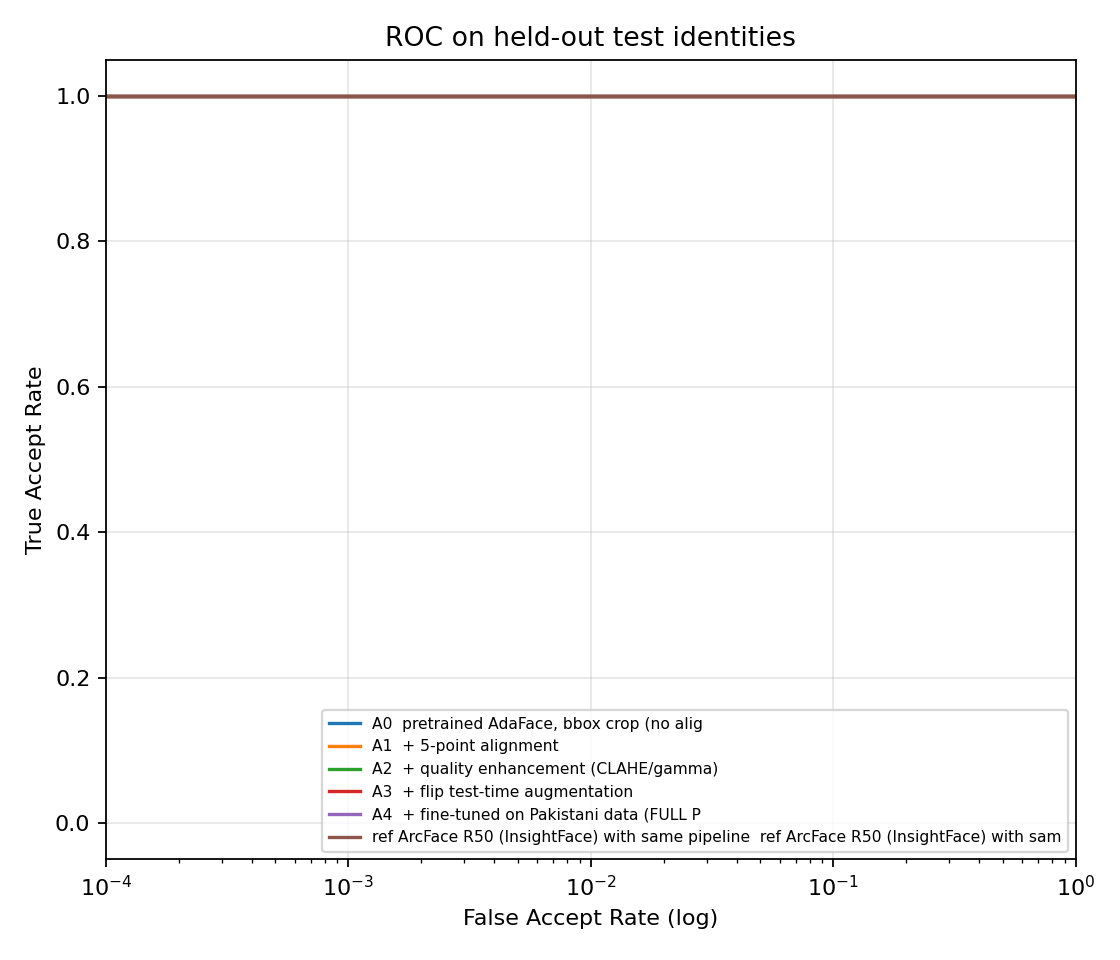

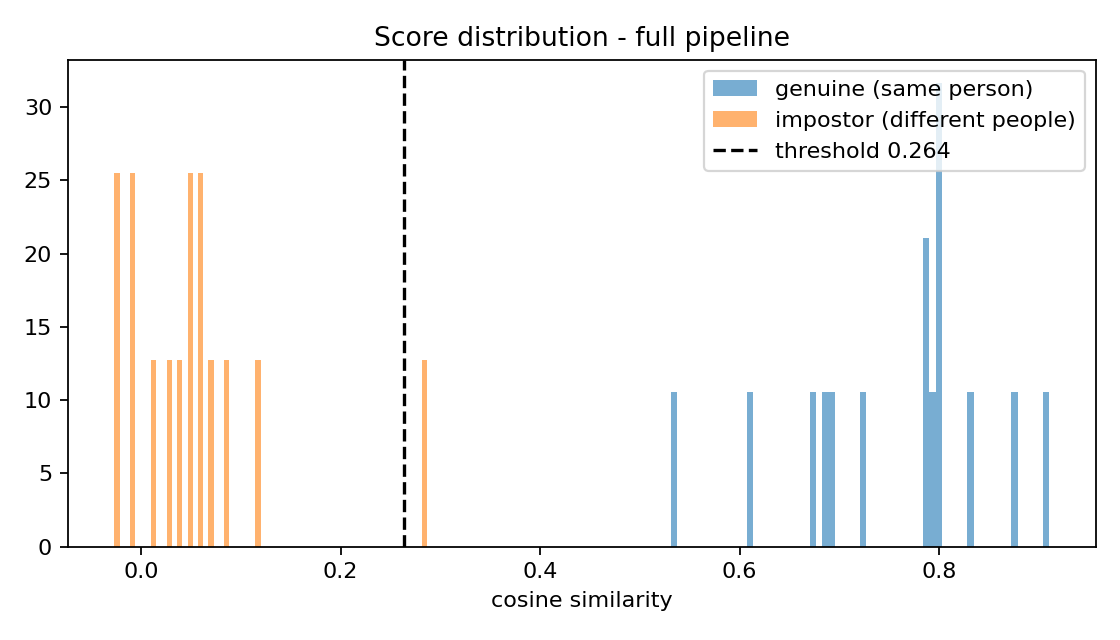

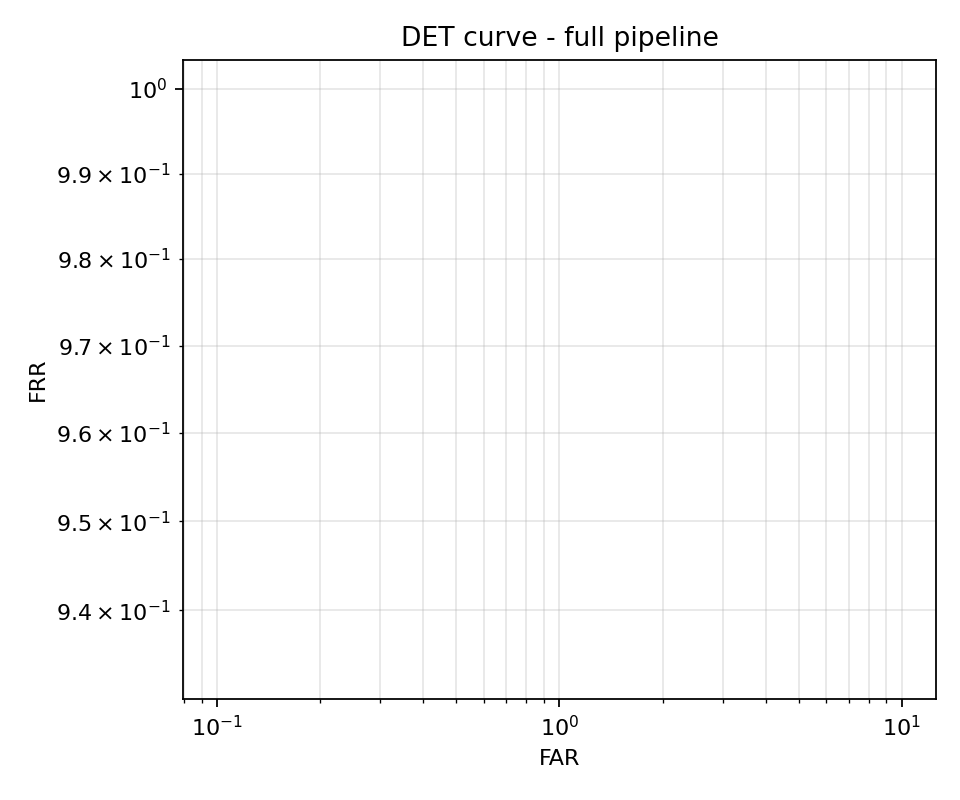

In [ ]:
from IPython.display import Image as IPImage
for f in ['roc_ablation.png', 'score_distribution.png', 'det_curve.png']:
    display(IPImage(f'{RUNS}/results/{f}', width=650))

## 6. Gallery of known people
Put 1-5 clear photos per person in `MyDrive/NemoFR/gallery_photos/<Name>/`. For a quick demo you can
enroll some of your own **test** volunteers (they were never trained on).

In [ ]:
!python scripts/enroll_gallery.py --adaface_repo {ADAFACE} --ckpt {FINETUNED} \
        --threshold_file {RUNS}/results/threshold.json --people {DRIVE}/gallery_photos \
        --gallery {RUNS}/gallery.npz --fresh

gallery with 0 people saved to /content/drive/MyDrive/NemoFR/runs/gallery.npz


## 7. Image or video in → recognised, cropped faces out

In [ ]:
# INPUT = f'{DRIVE}/samples/test.jpg'      # or a .mp4 / folder
INPUT = '/content/niqaab01.jpeg'
!python scripts/run_inference.py --adaface_repo {ADAFACE} --ckpt {FINETUNED} \
        --threshold_file {RUNS}/results/threshold.json --gallery {RUNS}/gallery.npz \
        --input "{INPUT}" --out {RUNS}/outputs
!ls {RUNS}/outputs

/content/niqaab01.jpeg: 1 face(s) -> /content/drive/MyDrive/NemoFR/runs/outputs/niqaab01_crops
niqaab01_annotated.jpg	niqaab01.json	      niqaab.json	  test_crops
niqaab01_crops		niqaab_annotated.jpg  test_annotated.jpg  test.json


## 8. Interactive demo (public link printed below)

In [ ]:
!python app.py --adaface_repo {ADAFACE} --ckpt {FINETUNED} \
        --threshold_file {RUNS}/results/threshold.json --gallery {RUNS}/gallery.npz

## 9. Hidden benchmark day (23 Oct)
Pick the mode that matches what the TechFest team gives you:

In [ ]:
# pairs CSV (img1,img2[,label]):
# !python scripts/benchmark.py pairs --pairs /content/bench/pairs.csv --root /content/bench \
#     --adaface_repo {ADAFACE} --ckpt {FINETUNED} --threshold_file {RUNS}/results/threshold.json --out {RUNS}/bench_preds.csv

# gallery + probes folders:
# !python scripts/benchmark.py identify --gallery_dir /content/bench/gallery --probe_dir /content/bench/probes \
#     --adaface_repo {ADAFACE} --ckpt {FINETUNED} --threshold_file {RUNS}/results/threshold.json --out {RUNS}/bench_preds.csv

# just detect + crop every face:
# !python scripts/benchmark.py crops --probe_dir /content/bench/images --adaface_repo {ADAFACE} --ckpt {FINETUNED} --out {RUNS}/bench_crops

## 10. Student pack — Face Embedding Challenge (graded: top-1 accuracy)
`embed()` in `make_submission.py` now uses **our pipeline** (SCRFD detect → align → quality → AdaFace IR-101 → flip-TTA → 512-d vector).
Output is `<group>.npz` with `train_ids, train_emb, test_ids, test_emb`.

**Before running:** upload `student_pack.zip` to `MyDrive/NemoFR/` (on lab day also upload `lab_pack` the same way).
This section only needs the two cells under **1. Setup** (mount Drive + weights) and `runs/ft/best.pt` on Drive — it does **not** need steps 2-8, so you can run it on its own. Use a **T4 GPU** runtime.

In [ ]:
# 10a. Locate the student pack, set your group name, pick the checkpoint
import os, glob, shutil, zipfile
GROUP = 'group05'                      # <-- CHANGE to your real group name (e.g. group05)

# unzip the pack from Drive (skip if you already uploaded the folder to /content)
if os.path.exists(f'{DRIVE}/student_pack.zip'):
    zipfile.ZipFile(f'{DRIVE}/student_pack.zip').extractall('/content/')
hits = glob.glob('/content/**/practice/train', recursive=True)
assert hits, 'student pack not found - upload student_pack.zip to MyDrive/NemoFR/'
PACK = os.path.dirname(os.path.dirname(hits[0]))
print('PACK =', PACK)

# fine-tuned weights if present, otherwise the pretrained AdaFace weights
CKPT = f'{RUNS}/ft/best.pt' if os.path.exists(f'{RUNS}/ft/best.pt') else PRETRAINED
print('CKPT =', CKPT)
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - switch runtime to GPU (CPU works but is slow)')

PACK = /content/drive/MyDrive/NemoFR (1)/student_pack
CKPT = /content/drive/MyDrive/NemoFR (1)/weights/adaface_ir_101_webface12m.ckpt
GPU: Tesla T4


In [ ]:
!python scripts/make_submission_grp.py group05 \
  "{DRIVE}/student_pack/practice" \
  --ckpt "{DRIVE}/weights/adaface_ir_101_webface12m.ckpt" \
  --adaface_repo "{ADAFACE}" \
  --key "{DRIVE}/student_pack/practice_key.csv"

download_path: /root/.insightface/models/buffalo_l
100% 281857/281857 [00:03<00:00, 92138.96KB/s]
/content/AdaFace/head.py:71: SyntaxWarning: invalid escape sequence '\A'
  print('\n\AdaFace with the following property')
multi-face photos: 4; face changed from the largest in 3: ['test/t_0001.jpg', 'test/t_0002.jpg', 'test/t_0006.jpg']
saved group05.npz (7, 512) (7, 512)
faces: 14 direct, 0 via retry, 0 NO FACE FOUND (fallback vector)
  t_0001.jpg -> abdul_qadeer_khan            sim=0.640  OK
  t_0002.jpg -> maryam_nawaz                 sim=0.588  OK
  t_0003.jpg -> shehbaz_sharif               sim=0.778  OK
  t_0004.jpg -> saeed_anwar                  sim=0.371  OK
  t_0005.jpg -> pervez_musharraf             sim=0.612  OK
  t_0006.jpg -> bilawal_bhutto_zardari       sim=0.338  OK
  t_0007.jpg -> zeba_bakhtiar                sim=0.485  OK
practice self-check: top-1 = 7/7 (100%), top-5 = 7/7 (100%)


In [ ]:
import os

DRIVE = "/content/drive/MyDrive/NemoFR (1)"

for root, dirs, files in os.walk(DRIVE):
    for file in files:
        if file.endswith(".npz"):
            print(os.path.join(root, file))

/content/drive/MyDrive/NemoFR (1)/runs/gallery.npz


In [ ]:
!unzip -oq "/content/Benchmark_Dataset.zip" -d "/content/Benchmark_Dataset"

In [ ]:
# 10c. LAB DAY - generate, validate, back up, download the .npz
import os, glob, shutil, numpy as np
from google.colab import files

DRIVE   = "/content/drive/MyDrive/NemoFR (1)"
RUNS    = f"{DRIVE}/runs"
ADAFACE = "/content/AdaFace"
GROUP   = "group05"                                              # <-- your real group name
CKPT    = f"{DRIVE}/weights/adaface_ir_101_webface12m.ckpt"      # same weights that gave 7/7 on practice
os.makedirs(RUNS, exist_ok=True)

# lab pack (finds it if it was unzipped one level deeper)
LAB = "/content/Benchmark_Dataset/Benchmark_Dataset"
if not (os.path.isdir(f"{LAB}/train") and os.path.isdir(f"{LAB}/test")):
    found = [p for p in glob.glob("/content/**/lab_pack/train", recursive=True)
             if os.path.isdir(os.path.join(os.path.dirname(p), "test"))]
    assert found, "lab_pack/train and lab_pack/test not found - upload and unzip the lab pack first"
    LAB = os.path.dirname(found[0])
print("LAB =", LAB)
print("train entries:", len(os.listdir(f"{LAB}/train")), "| test entries:", len(os.listdir(f"{LAB}/test")))
print("first train entries:", sorted(os.listdir(f"{LAB}/train"))[:5])

# the same script that passed practice (absolute paths)
cands = ["/content/facerec_pk/scripts/make_submission_grp.py",
         "/content/facerec_pk/scripts/make_submission.py"]
SCRIPT = next((p for p in cands if os.path.isfile(p)), None)
assert SCRIPT, f"submission script not found in {cands}"
print("Using script:", SCRIPT)

# pass an ABSOLUTE group path so the file is saved exactly at OUTPUT
OUT_BASE = f"/content/{GROUP}"
OUTPUT = OUT_BASE + ".npz"
!python "{SCRIPT}" "{OUT_BASE}" "{LAB}" --ckpt "{CKPT}" --adaface_repo "{ADAFACE}"
assert os.path.isfile(OUTPUT), f"Output not found: {OUTPUT}"

# validate (image files only, so stray files like .DS_Store cannot cause a false failure)
IMG = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
imgs = lambda d: sorted(f for f in os.listdir(d) if f.lower().endswith(IMG))
with np.load(OUTPUT, allow_pickle=False) as z:
    assert set(z.files) == {"train_ids", "train_emb", "test_ids", "test_emb"}, z.files
    assert z["train_emb"].shape[1] == z["test_emb"].shape[1], "embedding sizes differ"
    assert np.isfinite(z["train_emb"]).all() and np.isfinite(z["test_emb"]).all(), "NaN/inf found"
    assert list(z["train_ids"].astype(str)) == imgs(f"{LAB}/train"), "train IDs do not match folder"
    assert list(z["test_ids"].astype(str)) == imgs(f"{LAB}/test"), "test IDs do not match folder"
    print("Validation OK", z["train_emb"].shape, z["test_emb"].shape)

shutil.copy2(OUTPUT, f"{RUNS}/{GROUP}.npz")
print("Drive backup saved:", f"{RUNS}/{GROUP}.npz")
files.download(OUTPUT)

LAB = /content/Benchmark_Dataset/Benchmark_Dataset
train entries: 50 | test entries: 50
first train entries: ['abdul_sattar_edhi.jpg', 'abida_parveen.jpg', 'ahad_raza_mir.jpg', 'ali_zafar.jpg', 'arshad_nadeem.jpg']
Using script: /content/facerec_pk/scripts/make_submission_grp.py
multi-face photos: 7; face changed from the largest in 3: ['test/t_0008.jpg', 'test/t_0011.jpg', 'test/t_0027.jpg']
saved /content/group05.npz (50, 512) (50, 512)
faces: 100 direct, 0 via retry, 0 NO FACE FOUND (fallback vector)
Validation OK (50, 512) (50, 512)
Drive backup saved: /content/drive/MyDrive/NemoFR (1)/runs/group05.npz


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>